# Lab03 – Bài 2: Mô hình hóa bài toán n-Queens

**Sinh viên thực hiện:** Nguyễn Hữu Tri — **MSSV:** 3123410387  
**Môn học:** Trí tuệ nhân tạo nâng cao — **Đại học Sài Gòn**  
**Cơ sở:** `n_queens.ipynb` và hướng dẫn *TTNTNC – Lab03: Tìm kiếm cục bộ*.

**Phạm vi:** biểu diễn bàn cờ, hàm mục tiêu, toán tử lân cận, minh họa và kiểm thử trên $n=4,8$. **Chưa triển khai Task 1–5 (Bài 3–4)** và chưa làm báo cáo tổng.

**Khai báo hỗ trợ:** sử dụng ChatGPT để giải thích, thiết kế kiểm thử, viết và chạy notebook; kết quả được kiểm tra tự động bằng các `assert`. Người nộp cần đọc hiểu và tự xác nhận nội dung trước khi nộp.

## 1. Mục tiêu thực hành (theo yêu cầu Bài 2)

1. Khảo sát ba hàm được cung cấp: `random_board(n)`, `show_board(board)` và `conflicts(board)`.
2. Biểu diễn mỗi bàn cờ thành một vector độ dài $n$: cột $i$ có đúng một hậu tại hàng $q_i$.
3. Xác định nước đi lân cận: **đổi hàng của đúng một hậu trong cùng cột**, đếm số láng giềng.
4. Chạy $n=4$, $n=8$; so sánh bàn cờ ngẫu nhiên với **`[1, 3, 0, 2]`** ở $n=4$.
5. Giải thích vì sao cực tiểu hóa $f(q)=\mathrm{conflicts}(q)$, nghiệm hợp lệ cần $f(q)=0$.

Các phép chạy ngẫu nhiên mở rộng và kiểm chứng độc lập phía dưới giúp tránh chỉ đánh giá bằng một ví dụ may rủi.

## 2. Lý thuyết: trạng thái, hàm mục tiêu và lân cận

- **Trạng thái:** $q=[q_0,q_1,\ldots,q_{n-1}]$, với $q_i\in\{0,\ldots,n-1\}$. Chỉ số $i$ là **cột**, giá trị $q_i$ là **hàng** (đếm từ 0). Mỗi cột có đúng một hậu; **các hàng có thể trùng** trong trạng thái chưa giải xong.
- **Xung đột:** hai hậu tại cột $i<j$ tấn công nhau khi $q_i=q_j$ (cùng hàng) **hoặc** $|q_i-q_j|=j-i$ (cùng đường chéo). Xung đột theo cột không xảy ra do cách biểu diễn.
- **Hàm mục tiêu:** số **cặp** hậu xung đột, mỗi cặp chỉ đếm một lần:

$$
f(q)=\sum_{0\le i<j<n}\mathbf{1}\!\left[q_i=q_j\;\lor\;|q_i-q_j|=j-i\right],\qquad \min_q f(q).
$$

- **Lời giải:** một trạng thái thỏa $f(q)=0$.
- **Lân cận:** chọn cột $i$, thay $q_i$ bằng bất kỳ hàng khác $r\ne q_i$; mọi cột còn lại giữ nguyên. Số lựa chọn là $n(n-1)$ và mỗi láng giềng phân biệt với nhau.
- **Không gian trạng thái:** $n^n$ vector, vì mỗi trong $n$ cột có $n$ khả năng hàng; đây **không** phải $n!$, vốn chỉ đếm trạng thái có cả mỗi hàng đúng một hậu.

Vì bản đồ bàn cờ thường có $n\ge 4$ trong lab, ta khảo sát $n=4$ và $n=8$. Lưu ý câu khẳng định “mọi $n$ đều có nghiệm 0 xung đột” trong notebook mẫu có ngoại lệ $n=2,3$; thực nghiệm vét cạn nho nhỏ ở dưới cũng kiểm tra điều này.

## 3. Sử dụng lại các hàm gốc trong `n_queens.ipynb`

Cell kế tiếp **giữ nguyên định nghĩa** `random_board()`, `show_board()` và `conflicts()` từ notebook đi kèm đề. Nhờ vậy Bài 2 sử dụng cùng hàm mục tiêu với phần cài đặt Hill Climbing ở Bài 3–4.

Trong `conflicts()`, bộ đếm theo **hàng**, đường chéo $i+q_i$ và $i-q_i+n$ được cộng theo $\binom{k}{2}=k(k-1)/2$. Mỗi nhóm có $k$ hậu tạo đúng số cặp xung đột đó. Đây là cách đếm $O(n)$ trong mã gốc; phần đo tốc độ chuyên sâu thuộc **Bài 6**.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors

np.random.seed(1234)


def random_board(n):
    """Creates a random board of size n x n. Note that only a single queen is placed in each column!"""

    return(np.random.randint(0,n, size = n))

def comb2(n): return n*(n-1)//2 # this is n choose 2 equivalent to math.comb(n, 2); // is int division

def conflicts(board):
    """Calculate the number of conflicts, i.e., the objective function."""

    n = len(board)

    horizontal_cnt = [0] * n
    diagonal1_cnt = [0] * 2 * n
    diagonal2_cnt = [0] * 2 * n

    for i in range(n):
        horizontal_cnt[board[i]] += 1
        diagonal1_cnt[i + board[i]] += 1
        diagonal2_cnt[i - board[i] + n] += 1

    return sum(map(comb2, horizontal_cnt + diagonal1_cnt + diagonal2_cnt))

# decrease the font size to fit larger boards
def show_board(board, cols = ['white', 'gray'], fontsize = 48):  
    """display the board"""

    n = len(board)

    # create chess board display
    display = np.zeros([n,n])
    for i in range(n):
        for j in range(n):
            if (((i+j) % 2) != 0): 
                display[i,j] = 1

    cmap = colors.ListedColormap(cols)
    fig, ax = plt.subplots()
    ax.imshow(display, cmap = cmap, 
              norm = colors.BoundaryNorm(range(len(cols)+1), cmap.N))
    ax.set_xticks([])
    ax.set_yticks([])

    # place queens. Note: Unicode u265B is a black queen
    for j in range(n):
        plt.text(j, board[j], u"\u265B", fontsize = fontsize, 
                 horizontalalignment = 'center',
                 verticalalignment = 'center')

    print(f"Board with {conflicts(board)} conflicts.")
    plt.show()

## 4. Quan sát bàn cờ ngẫu nhiên với $n=4$ và $n=8$

Giữ `seed=1234` theo code mẫu để hai lần chạy notebook cho **cùng** ví dụ. Kết quả in dưới hình cho biết vector trạng thái và số xung đột. **Một trạng thái ngẫu nhiên không đại diện cho tỷ lệ thành công**; phần 8 sẽ chạy nhiều trạng thái để khảo sát.


Bàn cờ ngẫu nhiên n=4: [3, 3, 2, 1], conflicts=4
Board with 4 conflicts.


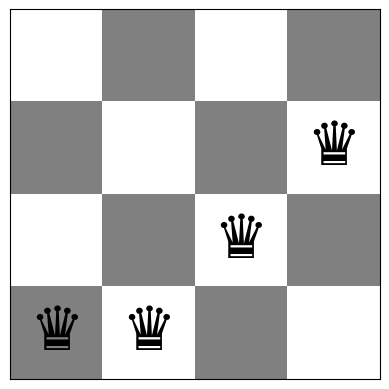


Bàn cờ ngẫu nhiên n=8: [4, 4, 0, 1, 7, 1, 7, 1], conflicts=8
Board with 8 conflicts.


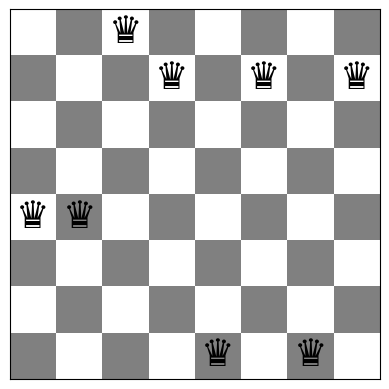

In [2]:
np.random.seed(1234)  # hàm random_board() của notebook mẫu dùng bộ sinh ngẫu nhiên NumPy toàn cục
board4 = random_board(4)
board8 = random_board(8)
for n, q in [(4, board4), (8, board8)]:
    print(f'\nBàn cờ ngẫu nhiên n={n}: {q.tolist()}, conflicts={conflicts(q)}')
    show_board(q, fontsize=44 if n == 4 else 27)

## 5. Đối chiếu với một cấu hình không xung đột

Đề yêu cầu so sánh với `board = [1, 3, 0, 2]` cho $n=4$; vector này là một nghiệm với 4 hậu. Bổ sung một nghiệm 8 hậu chỉ để xác nhận cùng một biểu diễn và hàm mục tiêu vẫn hoạt động trên $n=8$, không phải kết quả chạy thuật toán tìm kiếm.


Cấu hình đã biết n=4: [1, 3, 0, 2], conflicts=0
Board with 0 conflicts.


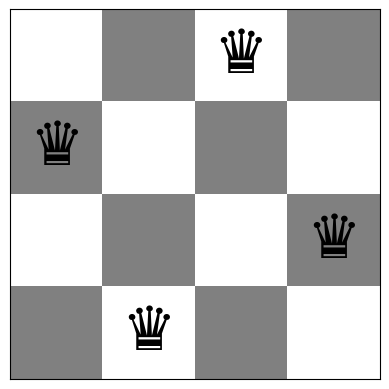


Cấu hình đã biết n=8: [0, 4, 7, 5, 2, 6, 1, 3], conflicts=0
Board with 0 conflicts.


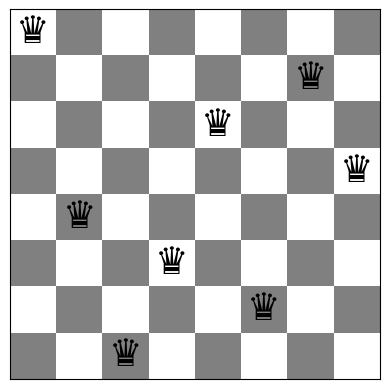

In [3]:
solution4 = np.array([1, 3, 0, 2], dtype=int)
solution8 = np.array([0, 4, 7, 5, 2, 6, 1, 3], dtype=int)
assert conflicts(solution4) == 0
assert conflicts(solution8) == 0
for n, q in [(4, solution4), (8, solution8)]:
    print(f'\nCấu hình đã biết n={n}: {q.tolist()}, conflicts={conflicts(q)}')
    show_board(q, fontsize=44 if n == 4 else 27)

## 6. Kích thước không gian tìm kiếm và số trạng thái láng giềng

Trong biểu diễn “một hậu trên mỗi cột”, **không được** tự ý hạn chế mỗi hàng một hậu trước khi sinh lân cận. Nếu chỉ cho các vector hoán vị, toán tử “đổi một hậu sang hàng khác trong cùng cột” có thể phá tính chất hoán vị, khiến định nghĩa bài toán không nhất quán.

| Đại lượng | Công thức | $n=4$ | $n=8$ |
|---|---:|---:|---:|
| Số trạng thái | $n^n$ | 256 | 16.777.216 |
| Số trạng thái lân cận | $n(n-1)$ | 12 | 56 |
| Số hoán vị hàng (chỉ là một tập con) | $n!$ | 24 | 40.320 |

Hàm `neighbors()` dưới đây dùng **phép gán sang hàng khác cùng cột**; trả về `(column, new_row, new_board)` để dễ kiểm tra nguồn gốc nước đi. Đây mới là **mô hình toán tử**, chưa phải thuật toán chọn bước đi Hill Climbing.

In [4]:
from math import factorial
import pandas as pd

def neighbors(board):
    """Sinh toàn bộ láng giềng hợp lệ: đổi một hậu sang hàng khác trong cùng cột."""
    q = np.asarray(board, dtype=int)
    n = len(q)
    if q.ndim != 1 or n < 1 or np.any((q < 0) | (q >= n)):
        raise ValueError('board phải là vector n phần tử, mỗi hàng thuộc [0, n-1].')
    for column in range(n):
        for new_row in range(n):
            if new_row == q[column]:
                continue
            candidate = q.copy()  # không chỉnh sửa trạng thái gốc
            candidate[column] = new_row
            yield (column, new_row, candidate)

space_table = pd.DataFrame([
    {'n': n, 'n^n (trạng thái)': n**n, 'n! (hoán vị)': factorial(n),
     'n(n−1) (lân cận)': n*(n-1)} for n in [4, 8]
])
display(space_table)
for n, q in [(4, board4), (8, board8)]:
    candidates = list(neighbors(q))
    print(f'n={n}: đếm được {len(candidates)} láng giềng; lý thuyết {n*(n-1)}')
    assert len(candidates) == n*(n-1)

,n,n^n (trạng thái),n! (hoán vị),n(n−1) (lân cận)
0,4,256,24,12
1,8,16777216,40320,56


n=4: đếm được 12 láng giềng; lý thuyết 12
n=8: đếm được 56 láng giềng; lý thuyết 56


## 7. Minh họa lân cận và chất lượng nước đi

Từ một bàn cờ ngẫu nhiên, có thể có nước đi làm **giảm**, **giữ nguyên** hoặc **tăng** số xung đột. Bài 2 mới nhận diện các nước đi; đến Bài 3, thuật toán Hill Climbing mới sử dụng hàm $f$ để quyết định chọn nước đi nào.

In [5]:
rows = []
for n, q in [(4, board4), (8, board8)]:
    base_f = conflicts(q)
    local_moves = list(neighbors(q))
    scores = np.array([conflicts(candidate) for _, _, candidate in local_moves])
    rows.append({'n': n, 'f(trạng thái gốc)': base_f,
                 'Cải thiện (Δ<0)': int((scores < base_f).sum()),
                 'Ngang (Δ=0)': int((scores == base_f).sum()),
                 'Xấu hơn (Δ>0)': int((scores > base_f).sum()),
                 'Tổng láng giềng': len(local_moves)})
neighbor_table = pd.DataFrame(rows)
display(neighbor_table)

print('Ví dụ 5 láng giềng đầu của bàn cờ n=4:')
for column, row, q in list(neighbors(board4))[:5]:
    print(f'Đổi cột {column} sang hàng {row}: {q.tolist()}, conflicts={conflicts(q)}')

,n,f(trạng thái gốc),Cải thiện (Δ<0),Ngang (Δ=0),Xấu hơn (Δ>0),Tổng láng giềng
0,4,4,6,4,2,12
1,8,8,25,11,20,56


Ví dụ 5 láng giềng đầu của bàn cờ n=4:
Đổi cột 0 sang hàng 0: [0, 3, 2, 1], conflicts=4
Đổi cột 0 sang hàng 1: [1, 3, 2, 1], conflicts=4
Đổi cột 0 sang hàng 2: [2, 3, 2, 1], conflicts=5
Đổi cột 1 sang hàng 0: [3, 0, 2, 1], conflicts=1
Đổi cột 1 sang hàng 1: [3, 1, 2, 1], conflicts=3


## 8. Kiểm chứng độc lập của hàm `conflicts()` và toán tử lân cận

Để tránh trường hợp hai hàm cùng mắc một lỗi, `conflicts_reference()` dưới đây dùng **duyệt từng cặp hậu**, khác với cách đếm bộ đếm của notebook gốc. Kiểm tra:

- Các cấu hình có giá trị xung đột đã biết.
- **Vét cạn tất cả 256 trạng thái n=4**, so sánh hai cách đếm và xác định có bao nhiêu nghiệm.
- Thử thêm 1.000 trạng thái n=8 với seed cố định.
- Xác minh mỗi láng giềng khác trạng thái gốc ở **chính xác một cột**, không thay đổi board ban đầu và không trùng lặp.

In [6]:
from itertools import product

def conflicts_reference(board):
    q = np.asarray(board)
    n = len(q)
    return sum(int(q[i] == q[j] or abs(int(q[i]) - int(q[j])) == j - i)
               for i in range(n) for j in range(i + 1, n))

known_cases = [([1, 3, 0, 2], 0), ([0, 0, 0, 0], 6),
               ([0, 1, 2, 3], 6), ([0, 4, 7, 5, 2, 6, 1, 3], 0)]
for q, expected in known_cases:
    assert conflicts(q) == conflicts_reference(q) == expected

solutions4 = []
for positions in product(range(4), repeat=4):
    assert conflicts(positions) == conflicts_reference(positions)
    if conflicts(positions) == 0:
        solutions4.append(positions)
assert set(solutions4) == {(1, 3, 0, 2), (2, 0, 3, 1)}

rng_check = np.random.default_rng(20261016)
for _ in range(1000):
    q = rng_check.integers(0, 8, size=8)
    assert conflicts(q) == conflicts_reference(q)

for n, start in [(4, board4), (8, board8)]:
    initial = np.array(start, copy=True)
    moves = list(neighbors(initial))
    different = {tuple(candidate) for _, _, candidate in moves}
    assert len(moves) == len(different) == n*(n-1)
    assert all(np.count_nonzero(candidate != initial) == 1 for _, _, candidate in moves)
    assert all(np.all((candidate >= 0) & (candidate < n)) for _, _, candidate in moves)
    assert np.array_equal(initial, start)

print('PASS: đối chiếu 256/256 bàn cờ n=4 và 1000/1000 bàn cờ n=8.')
print('PASS: số láng giềng, không trùng lặp, đúng một cột thay đổi, giữ nguyên board gốc.')
print('Hai nghiệm n=4 tìm bằng vét cạn:', solutions4)

PASS: đối chiếu 256/256 bàn cờ n=4 và 1000/1000 bàn cờ n=8.
PASS: số láng giềng, không trùng lặp, đúng một cột thay đổi, giữ nguyên board gốc.
Hai nghiệm n=4 tìm bằng vét cạn: [(1, 3, 0, 2), (2, 0, 3, 1)]


## 9. Khảo sát mở rộng: phân phối xung đột của bàn cờ ngẫu nhiên

Để đánh giá **trạng thái khởi tạo**, lấy 1.000 board ngẫu nhiên cho mỗi $n=4$ và $n=8$ bằng `np.random.default_rng` với các seed độc lập. Đếm số xung đột và tỷ lệ tình cờ tạo được $f=0$.

Thử nghiệm này **không đo hiệu quả Hill Climbing** (vì chưa chạy thuật toán tìm kiếm). Với 1.000 lượt, n=8 có thể không có nghiệm ngẫu nhiên; số lần bằng 0 trong mẫu **không chứng minh xác suất lý thuyết bằng 0**.

In [7]:
random_samples = {}
record = []
for n in (4, 8):
    rng = np.random.default_rng(20261016 + n)
    samples = np.array([conflicts(rng.integers(0, n, size=n)) for _ in range(1000)])
    random_samples[n] = samples
    record.append({'n': n, 'Số lần': len(samples), 'f trung bình': round(float(samples.mean()), 3),
                   'f nhỏ nhất': int(samples.min()), 'f lớn nhất': int(samples.max()),
                   'Số lần f=0': int((samples == 0).sum()),
                   'Tỷ lệ f=0 (%)': round(100 * float((samples == 0).mean()), 2)})
random_table = pd.DataFrame(record)
display(random_table)

,n,Số lần,f trung bình,f nhỏ nhất,f lớn nhất,Số lần f=0,Tỷ lệ f=0 (%)
0,4,1000,3.250,0,6,13,1.3
1,8,1000,7.859,2,16,0,0.0


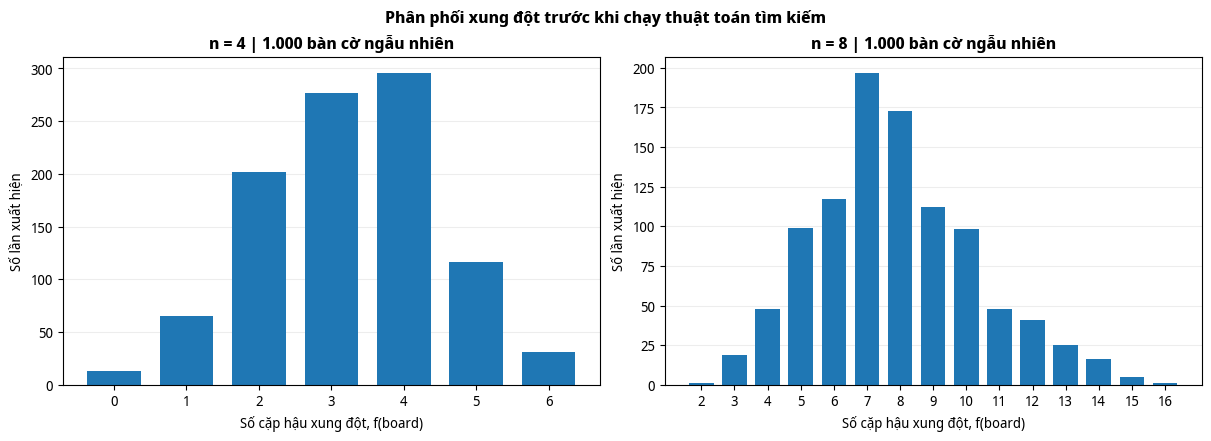

In [8]:
# Hình thực nghiệm: biểu đồ tần suất giá trị f của 1.000 board ngẫu nhiên.
plt.rcParams['font.family'] = 'Noto Sans Display'
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), layout='constrained')
for ax, n in zip(axes, (4, 8)):
    samples = random_samples[n]
    levels, counts = np.unique(samples, return_counts=True)
    ax.bar(levels, counts, width=0.74)
    ax.set_title(f'n = {n} | 1.000 bàn cờ ngẫu nhiên', weight='bold')
    ax.set_xlabel('Số cặp hậu xung đột, f(board)')
    ax.set_ylabel('Số lần xuất hiện')
    ax.set_xticks(levels)
    ax.grid(axis='y', alpha=0.22)
    ax.set_axisbelow(True)
plt.suptitle('Phân phối xung đột trước khi chạy thuật toán tìm kiếm', fontsize=12, weight='bold')
plt.show()

## 10. Nhận xét và kết luận Bài 2

**(1) Biểu diễn trạng thái.** Vector $q$ có đúng một phần tử cho mỗi cột, nên không cần kiểm tra xung đột theo cột. Hai hậu vẫn có thể trùng hàng hoặc đường chéo, vì vậy không nên giới hạn vector thành hoán vị trước khi tìm kiếm.

**(2) Hàm mục tiêu.** `conflicts()` đếm **cặp** tấn công nhau: bằng 0 là nghiệm hợp lệ, dương là cấu hình cần cải thiện. Kiểm chứng độc lập xác nhận hàm gốc khớp cách đếm từng cặp trên mọi board n=4 và 1.000 board n=8.

**(3) Toán tử lân cận.** Mỗi nước đi đổi hàng cho **chính xác một quân** nhưng giữ nguyên cột. Điều đó tạo $n(n-1)$ láng giềng: 12 khi $n=4$, 56 khi $n=8$. Bài 3 sẽ áp dụng các chính sách **chọn** lân cận, còn Bài 2 chỉ mô hình hóa và kiểm tra chúng.

**(4) Minh họa nghiệm.** `[1,3,0,2]` là nghiệm $n=4$ với $f=0$; vét cạn 256 trạng thái cho đúng hai nghiệm trong cách biểu diễn đang xét. Vì vậy xác suất chính xác khi chọn đều ngẫu nhiên một vector n=4 là $2/256=0{,}78125\%$. Trong 1.000 lần thử bên trên, tỷ lệ mẫu 1,3% có thể lệch do dao động thống kê; **không** thể coi đây là sự cải thiện do thuật toán tìm kiếm (vì chưa có thuật toán tìm kiếm nào được chạy).

**(5) Giới hạn và bước tiếp theo.** Không thể đánh giá Hill Climbing tốt hay kém chỉ từ số xung đột của trạng thái ban đầu; cần triển khai và đo các thuật toán Bài 3–4 với nhiều seed, cùng điều kiện dừng và cùng hàm mục tiêu.

**Kiểm tra ngoại lệ từ notebook mẫu:** Không tồn tại nghiệm $f=0$ cho $n=2,3$. Nhận định “mọi $n$ có nghiệm” trong phần giới thiệu của notebook chỉ đúng với $n=1$ hoặc $n\ge4$. Điều này không ảnh hưởng hai kích thước $n=4,8$ được yêu cầu trong lab.

In [9]:
# Kiểm chứng nhỏ cho lưu ý về n=2 và n=3 trong đoạn nhận xét.
for n in (2, 3):
    best = min(conflicts(board) for board in product(range(n), repeat=n))
    assert best > 0
    print(f'n={n}: f nhỏ nhất khi vét cạn = {best} (>0, không có nghiệm).')
print('HOÀN THÀNH BÀI 2 — toàn bộ kiểm thử đều đạt.')

n=2: f nhỏ nhất khi vét cạn = 1 (>0, không có nghiệm).
n=3: f nhỏ nhất khi vét cạn = 1 (>0, không có nghiệm).
HOÀN THÀNH BÀI 2 — toàn bộ kiểm thử đều đạt.
